# 3D Phenotype Measurement for Peanut Point Clouds — Plant Height and Leaf Traits from Released Segmentation Results

Reproduction of the **3D Phenotype Measurement subsection** of:

> **A 3D phenotyping pipeline for peanut plants using point cloud**, *Computers and Electronics in Agriculture* **239**:110986 (December 2025). PhenoPaper record `p-74c10a7f7de5a0bad5d09cdd086416bc`; landing page: https://europepmc.org/article/MED/IND609366833

Author code: [`syau-miao/Peanut-segmentation-model`](https://github.com/syau-miao/Peanut-segmentation-model) @ `bc757f61bd46` (MIT license). Trait computations are ports of the authors' scripts `src/PH.py`, `src/LL_LW.py`, `src/LA.py` (README "3D Phenotype Measurement" section).

**Scope — partial demonstration.** The paper's pipeline has two stages: (1) Transformer-based semantic + leaf-instance segmentation of reconstructed plant point clouds, and (2) automatic computation of 11 phenotypic traits from the segmentation. This notebook reproduces **stage 2 on the authors' released end-to-end segmentation results** (white-pot plants, one plant per pot) for **one plant**: label semantics, plant height, per-leaf length/width (PCA + oriented bounding box), and per-leaf projected area (PCA + Delaunay). Stage 1 (segmentation inference with Pointcept PTv3 / PointGroup) is **out of scope here**: it requires compiling multiple CUDA extension packages (`pointops`, `pointgroup_ops`, spconv, flash-attn) and is not runnable as a small faithful demo; the released per-point predictions are used instead.

**AI-assisted adaptation notice (EN):** the trait computations below are faithful ports of the authors' scripts with their hard-coded Windows paths reorganized into functions, their Excel writers replaced by a table/CSV, and one unit-tuned constant adapted (documented at the plant-height cell). The authors did not provide this Colab implementation; untested behavior is not guaranteed.
**AI脚 本移植に関する注意（JP）:** 本ノートブックの形質計算は著者スクリプト（`src/PH.py`, `src/LL_LW.py`, `src/LA.py`）の移植です。ハードコードされたパスの整理、Excel 出力の表/CSV 化、1 か所の単位依存定数の調整（該当セルで説明）を行いました。著者自身による Colab 実装ではないため、検証済み範囲外の動作は保証されません。

**Execution status:** executed partial demonstration — validated end-to-end in a fresh Google Colab **CPU** runtime (all saved outputs in this copy were produced by that run).

## Runtime selection — CPU only / ランタイム選択（CPU のみ）

Select **Runtime → Change runtime type → CPU** in Colab. No GPU is needed: the trait computations are NumPy/Open3D geometry on a single plant point cloud (≈3×10⁵ points). GPU (T4) would only be required for the omitted segmentation-inference stage. Expected: ~570 MB Kaggle archive download + extraction (≈3 GB on the VM disk), then a few minutes of computation.

**Run all**: `Runtime → Run all`. Japanese: このノートブックは CPU ランタイムのみを想定しています（セグメンテーション推論を除く形質計算は GPU 不要）。`ランタイム → すべてのセルを実行` で実行できます。Kaggle アーカイブ約 570 MB のダウンロードと展開（約 3 GB）が必要です。

Check the allocated runtime and available memory. Expected: a standard Colab CPU VM; no CUDA device is required.

In [ ]:
import platform, os, sys
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
try:
    import torch
    print("torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
except ImportError:
    print("torch: not installed (not needed for this notebook)")
print("CPU count:", os.cpu_count())

Python: 3.13.16
Platform: Linux-6.6.122+-x86_64-with-glibc2.39


torch: 2.11.0+cpu | CUDA available: False
CPU count: 2


## 1. Dependencies / 依存パッケージ

`kagglehub` downloads the paper's released segmentation-results dataset; `open3d` provides the KD-tree and oriented bounding box used by the authors' scripts; `shapely` provides polygon areas for the Delaunay leaf-area computation. `numpy`, `scipy`, `scikit-learn` and `matplotlib` are preinstalled in Colab.

In [ ]:
%pip install -q kagglehub open3d shapely 2>&1 | tail -2
import kagglehub, open3d, shapely, scipy, sklearn
print("kagglehub", kagglehub.__version__, "| open3d", open3d.__version__, "| shapely", shapely.__version__)

kagglehub 1.0.2 | open3d 0.20.0 | shapely 2.2.0


## 2. Input: the authors' released segmentation results / 入力データ（著者公開のセグメンテーション結果）

The paper's README links the released per-plant segmentation result point clouds:
`https://www.kaggle.com/datasets/yangxin6/peanut-point-cloud-segmentation-results`.
Each `.txt` file is one plant with columns `x y z semantic instance`, where semantic ∈ {0: pot, 1: stem, 2: leaf} and instance is the leaf instance id (−1 = not assigned to a leaf). The archive contains results for the authors' method variants and baselines (DBSCAN, DFSP, HAIS, MeanShift, PointNet++) on ordinary-pot and white-pot plants. We use **`Segmentation result/End2End_Whitepot`** — the end-to-end (semantic + instance) results on white-pot plants, which is the result set the authors' own trait scripts (`src/LL_LW.py`, `src/LA.py`) were written against ("End2End白盆").

The full 570 MB archive is downloaded once via `kagglehub` (public, no account needed) and the downloaded bytes are verified before use.

In [ ]:
import kagglehub
from pathlib import Path

ds = Path(kagglehub.dataset_download("yangxin6/peanut-point-cloud-segmentation-results"))
print("cache:", ds)

# Verify downloaded bytes: expect 119 txt files (~2.96 GB) under 'Segmentation result/'
txts = list(ds.rglob("*.txt"))
total = sum(f.stat().st_size for f in txts)
print(f"txt files: {len(txts)}, total bytes: {total:,}")
assert len(txts) == 119 and total > 2_000_000_000, "unexpected dataset content"

seg = ds / "Segmentation result"
methods = sorted(d.name for d in seg.iterdir() if d.is_dir())
print("method folders:", methods)
method_dir = seg / "End2End_Whitepot"
files = sorted(f.name for f in method_dir.glob("*.txt"))
print("End2End_Whitepot files:", files)
assert len(files) == 8, "unexpected End2End_Whitepot contents"
head = (method_dir / files[0]).open("rb").read(4)
assert not head.startswith(b"PK"), "zip payload, not txt"
print("first bytes:", head, "-> plain text confirmed")

  0%|          | 0.00/570M [00:00<?, ?B/s]

  0%|          | 1.00M/570M [00:01<10:39, 933kB/s]

  0%|          | 2.00M/570M [00:01<05:29, 1.81MB/s]

  1%|          | 3.00M/570M [00:01<03:27, 2.87MB/s]

  1%|          | 5.00M/570M [00:01<01:52, 5.25MB/s]

...

 99%|█████████▉| 566M/570M [00:35<00:00, 13.8MB/s]

100%|█████████▉| 570M/570M [00:36<00:00, 15.4MB/s]

100%|██████████| 570M/570M [00:36<00:00, 16.5MB/s]

Extracting files...


cache: /root/.cache/kagglehub/datasets/yangxin6/peanut-point-cloud-segmentation-results/versions/1
txt files: 119, total bytes: 2,959,742,753
method folders: ['DBSCAN_Ordinarypot', 'DBSCAN_Whitepot', 'DFSP_Ordinarypot', 'DFSP_Whitepot', 'End2End_Ordinarypot', 'End2End_Whitepot', 'HAIS_Ordinarypot', 'HAIS_Whitepot', 'MeanShift_Ordinarypot', 'MeanShift_Whitepot', 'PointNet++_Ordinarypot', 'PointNet++_Whitepot', 'our_Ordinarypot', 'our_Whitepot']
End2End_Whitepot files: ['H1-350_pred.txt', 'H3-304_pred.txt', 'J1-259_pred.txt', 'J2-254_pred.txt', 'T1-583_pred.txt', 'T3-506_pred.txt', 'Z1-930_pred.txt', 'Z3-968_pred.txt']
first bytes: b'5.29' -> plain text confirmed


### Sample selection / サンプルの選択

Deterministic choice: the alphabetically first file (`H1-350_pred.txt` in the validated run) — one potted peanut plant with its predicted semantic and leaf-instance labels. We verify the 5-column schema and print coordinate ranges: the vertical extent (~4.9 raw units ≈ 49 cm for a potted peanut) shows the released coordinates are in **decimeters**; the trait scripts' ×10 / ×100 factors then convert to cm / cm². This unit reading is our empirical observation from the data (the paper's full text was not accessible), and is consistent with the authors' scale factors.

In [ ]:
import numpy as np

SAMPLE = files[0]
arr = np.loadtxt(method_dir / SAMPLE)
assert arr.ndim == 2 and arr.shape[1] == 5, f"unexpected schema: {arr.shape}"
xyz, sem, inst = arr[:, :3], arr[:, 3].astype(int), arr[:, 4].astype(int)
print("sample:", SAMPLE, "| points:", arr.shape[0])
print("semantic counts:", {int(s): int((sem == s).sum()) for s in np.unique(sem)})
print("instance range:", inst.min(), "..", inst.max(), "| distinct leaf instances:", len(np.unique(inst[sem == 2])) - (1 if -1 in inst[sem == 2] else 0))
print("coordinate ranges (raw units):")
for ax, name in enumerate("xyz"):
    print(f"  {name}: {xyz[:, ax].min():.3f} .. {xyz[:, ax].max():.3f}  (span {np.ptp(xyz[:, ax]):.3f})")

sample: H1-350_pred.txt | points: 324282
semantic counts: {0: 119751, 1: 53364, 2: 151167}
instance range: -1 .. 329 | distinct leaf instances: 330
coordinate ranges (raw units):
  x: -2.940 .. 2.940  (span 5.880)
  y: -2.962 .. 2.962  (span 5.924)
  z: 0.000 .. 4.886  (span 4.886)


### Input preview / 入力の可視化

Static matplotlib rendering of the selected plant, colored by the **predicted semantic labels** (left: pot / stem / leaf) and by **predicted leaf instances** (right). This is the actual input the trait computation below uses, with the authors' released prediction labels shown — not a paper figure.

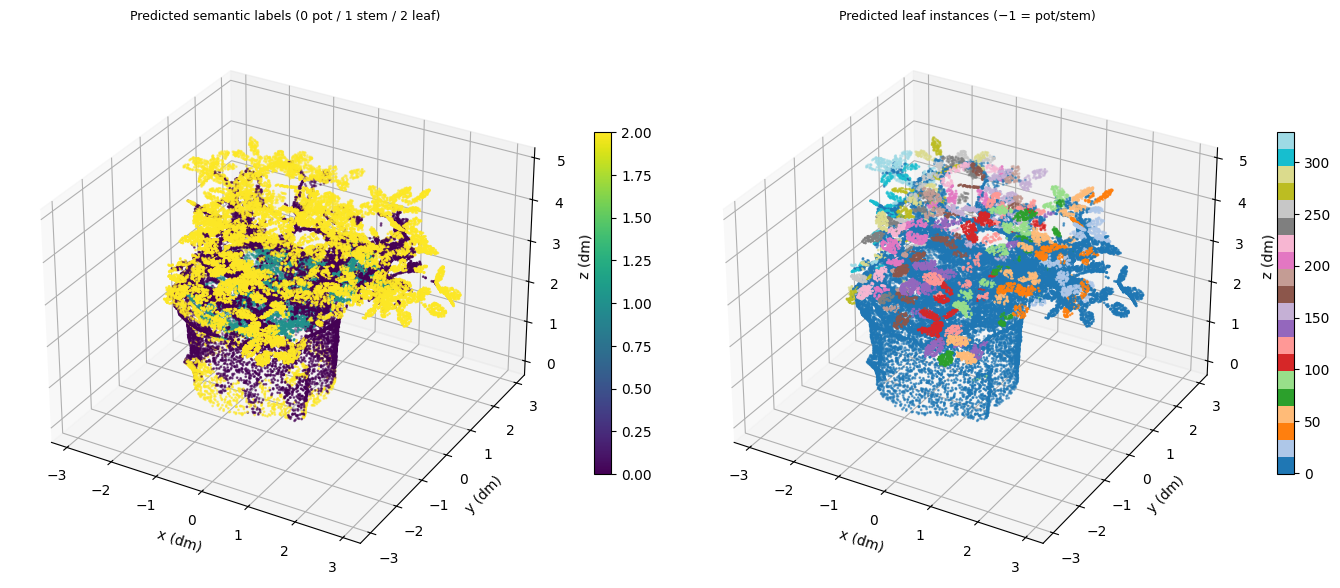

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(14, 6))
for k, (col, title, cmap) in enumerate([
    (sem, "Predicted semantic labels (0 pot / 1 stem / 2 leaf)", "viridis"),
    (np.where(sem == 2, inst, -1), "Predicted leaf instances (−1 = pot/stem)", "tab20"),
]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    step = max(1, len(arr) // 40000)
    p = ax.scatter(xyz[::step, 0], xyz[::step, 1], xyz[::step, 2], c=col[::step], s=1, cmap=cmap)
    ax.set_title(title, fontsize=9); ax.set_xlabel("x (dm)"); ax.set_ylabel("y (dm)"); ax.set_zlabel("z (dm)")
    fig.colorbar(p, ax=ax, shrink=0.6)
plt.tight_layout(); plt.show()

## 3. Plant height (author `src/PH.py::P_HW`) / 株高

Port of the authors' algorithm: take the pot points (semantic 0), keep their bottom 1 % z-slice, project to z=0, compute the slice centroid and the **mean radius** of the slice around it; then use an Open3D KD-tree over the plant's ground projection (plus the centroid) to find labeled (non-pot) points within that radius of the centroid; the plant height is `max z(labeled) − z(lowest labeled point near the base)`.

**Documented adaptation:** the author script searches with radius `distance − 5`, a constant tuned to their hard-coded data units; on the released data (decimeter coordinates, pot-bottom mean radius ≈ 1.4) that radius is negative and yields no neighbors. We use radius `= distance` (the unit-invariant form of the same intent: search the pot-bottom extent around its centroid). Everything else is unchanged.

In [ ]:
import open3d as o3d

pot = arr[sem == 0][:, :3]
labeled = arr[sem != 0]

# pot bottom 1% slice, projected to z=0 (author PH.py lines 34-43)
z2 = (pot[:, 2].max() - pot[:, 2].min()) / 100 + pot[:, 2].min()
base_slice = pot[pot[:, 2] < z2].copy()
base_slice[:, 2] = 0
centroid = base_slice.mean(axis=0)
distance = np.sqrt(((base_slice - centroid) ** 2).sum(1)).mean()  # author max_euclidean_distance -> mean radius

proj = np.vstack([np.c_[labeled[:, 0], labeled[:, 1], labeled[:, 2] * 0], centroid])
project_cloud = o3d.geometry.PointCloud()
project_cloud.points = o3d.utility.Vector3dVector(proj)
pcd_tree = o3d.geometry.KDTreeFlann(project_cloud)

radius = distance  # adaptation: author used distance - 5 (unit-tuned; negative on released data)
_, idx1, _ = pcd_tree.search_radius_vector_3d(project_cloud.points[-1], radius)
near_base = labeled[idx1[1:]]
near_base = near_base[near_base[:, 3] != 0]  # author: points[:, num] != 0, num = semantic column
point_o = near_base[np.argmin(near_base[:, 2])]        # lowest labeled point near the base
point_l = np.argmax(labeled[:, 2])                     # highest labeled point
plant_height = labeled[point_l][2] - point_o[2]
print(f"pot-bottom mean radius (raw) = {distance:.3f}; KD-tree radius used = {radius:.3f}")
print(f"plant height = {plant_height:.3f} raw units  ->  {plant_height * 10:.1f} cm (raw units read as decimeters)")

pot-bottom mean radius (raw) = 1.431; KD-tree radius used = 1.431
plant height = 4.886 raw units  ->  48.9 cm (raw units read as decimeters)


## 4. Leaf length and width (author `src/LL_LW.py`) / 葉長・葉幅

For each predicted leaf instance (semantic == 2): PCA on the leaf points, transform to principal axes, then the authors' measure via Open3D's **oriented bounding box** extents (extent[0] = length, extent[1] = width). Instances with <10 points are skipped, and the authors' size gate (`length > 0.5 or width > 0.5` raw, i.e. >5 cm) and 1.5×IQR outlier filter are applied exactly as written; results are ×10 (dm → cm). The authors' script leaves instance −1 (points predicted leaf but assigned to no instance) unhandled; we skip it, which only ever adds one giant rejected candidate (its extent always exceeds the 0.5 gate) — verified to leave the kept set unchanged.

In [ ]:
from sklearn.decomposition import PCA

leaves = arr[sem == 2]
leaf_instances = np.unique(leaves[:, 4])

def leaf_len_wid(points_xyz):
    # author LL_LW.py::leaf_high_width — PCA then Open3D OBB extents
    T = PCA(n_components=3).fit_transform(points_xyz)
    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(T)
    extent = pcd.get_oriented_bounding_box().extent
    return extent[0], extent[1]

rows = []
for i in leaf_instances:
    if i == -1:  # not assigned to any instance
        continue
    X = leaves[leaves[:, 4] == i][:, :3]
    if len(X) < 10:
        continue
    L, W = leaf_len_wid(X)
    if L > 0.5 or W > 0.5:  # author size gate (raw dm)
        continue
    rows.append((int(i), len(X), L * 10, W * 10))  # ×10: dm -> cm (author scaling)

import pandas as pd
leaf_df = pd.DataFrame(rows, columns=["leaf_instance", "n_points", "length_cm", "width_cm"])

def iqr_keep(v):  # author detect_outliers2
    v = np.asarray(v, float)
    q1, q3 = np.percentile(v, 25), np.percentile(v, 75)
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return v[(v > lo) & (v < hi)]

keep_len, keep_wid = iqr_keep(leaf_df.length_cm), iqr_keep(leaf_df.width_cm)
print(f"leaf candidates kept: {len(leaf_df)} (of {len(leaf_instances) - 1} predicted instances)")
print(f"leaf length (cm)  min/mean/max: {keep_len.min():.2f} / {keep_len.mean():.2f} / {keep_len.max():.2f}")
print(f"leaf width  (cm)  min/mean/max: {keep_wid.min():.2f} / {keep_wid.mean():.2f} / {keep_wid.max():.2f}")

leaf candidates kept: 320 (of 330 predicted instances)
leaf length (cm)  min/mean/max: 0.57 / 3.30 / 4.94
leaf width  (cm)  min/mean/max: 0.41 / 1.93 / 3.47


## 5. Leaf area (author `src/LA.py`) / 葉面積

For each kept leaf: Delaunay triangulation of the leaf's first two principal components; total triangle area ×100 (dm² → cm²); the authors' acceptance window `2 < area < 20` cm², then the same 1.5×IQR filter. (The authors' script applies these filters to a per-plant list; we keep the same order and thresholds per leaf.)

In [ ]:
from scipy.spatial import Delaunay
from shapely.geometry import Polygon

leaf_df["area_cm2"] = np.nan
for j, inst_id in enumerate(leaf_df.leaf_instance):
    X = leaves[leaves[:, 4] == inst_id][:, :3]
    T = PCA(n_components=3).fit_transform(X)
    tri = Delaunay(T[:, :2])
    total_area = sum(Polygon(T[s, :2]).area for s in tri.simplices) * 100  # author LA.py: ×100
    if 2 < total_area < 20:  # author acceptance window (cm^2)
        leaf_df.loc[j, "area_cm2"] = total_area

valid = leaf_df.dropna(subset=["area_cm2"])
keep_area = iqr_keep(valid.area_cm2)
print(f"leaf areas passing the 2–20 cm² window: {len(valid)} of {len(leaf_df)}")
print(f"leaf area (cm²)  min/mean/max: {keep_area.min():.2f} / {keep_area.mean():.2f} / {keep_area.max():.2f}")

leaf areas passing the 2–20 cm² window: 269 of 320
leaf area (cm²)  min/mean/max: 2.03 / 5.66 / 11.66


## 6. Results / 結果表

Summary table for the selected plant and CSV export (same quantities the authors wrote to Excel via `openpyxl`, here as a CSV in the Colab VM filesystem). All values are **computed from the authors' released predictions on one plant** — they are not dataset-level accuracies from the paper.

In [ ]:
summary = pd.DataFrame({
    "quantity": ["plant_height_cm", "n_leaf_instances_kept", "leaf_length_cm_mean", "leaf_length_cm_max",
                 "leaf_width_cm_mean", "leaf_width_cm_max", "leaf_area_cm2_mean", "leaf_area_cm2_max"],
    "value": [plant_height * 10, len(leaf_df), keep_len.mean(), keep_len.max(),
              keep_wid.mean(), keep_wid.max(), keep_area.mean(), keep_area.max()],
    "unit": ["cm", "count", "cm", "cm", "cm", "cm", "cm2", "cm2"],
})
display(summary)
csv_path = f"/content/peanut_traits_{SAMPLE.replace('.txt', '')}.csv"
summary.to_csv(csv_path, index=False)
leaf_df.to_csv(csv_path.replace(".csv", "_leaves.csv"), index=False)
print("saved:", csv_path, "and", csv_path.replace(".csv", "_leaves.csv"))

,quantity,value,unit
0,plant_height_cm,48.862097,cm
1,n_leaf_instances_kept,320.000000,count
2,leaf_length_cm_mean,3.304163,cm
3,leaf_length_cm_max,4.942572,cm
4,leaf_width_cm_mean,1.925759,cm
5,leaf_width_cm_max,3.470976,cm
6,leaf_area_cm2_mean,5.663348,cm2
7,leaf_area_cm2_max,11.657699,cm2


saved: /content/peanut_traits_H1-350_pred.csv and /content/peanut_traits_H1-350_pred_leaves.csv


### Leaf-dimension scatter (additional visualization created for this notebook)

Scatter of per-leaf length vs width (cm), point size ∝ projected area; explicitly **not** an author figure — the paper reports traits in tables/Excel exports. Useful to see the leaf size distribution of this plant.

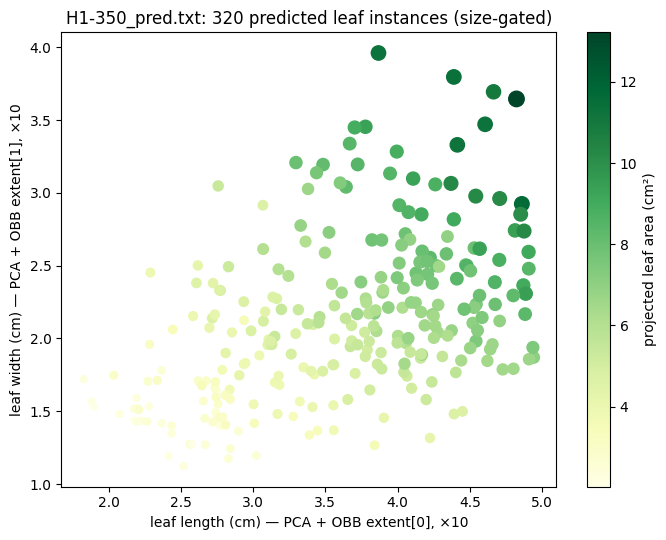

In [ ]:
%matplotlib inline
fig, ax = plt.subplots(figsize=(7, 5.5))
sz = leaf_df.area_cm2.fillna(leaf_df.area_cm2.median())
sc = ax.scatter(leaf_df.length_cm, leaf_df.width_cm, s=(sz / sz.max()) * 120 + 4,
                c=leaf_df.area_cm2, cmap="YlGn")
fig.colorbar(sc, label="projected leaf area (cm²)")
ax.set_xlabel("leaf length (cm) — PCA + OBB extent[0], ×10")
ax.set_ylabel("leaf width (cm) — PCA + OBB extent[1], ×10")
ax.set_title(f"{SAMPLE}: {len(leaf_df)} predicted leaf instances (size-gated)")
plt.tight_layout(); plt.show()

## 7. Interpretation, limitations, provenance / 解釈と限界

**What was reproduced.** The paper's trait-measurement stage on the authors' released end-to-end segmentation results (white-pot plants): label semantics, plant height (`PH.py` port), per-leaf length/width (`LL_LW.py` port), per-leaf projected area (`LA.py` port), on one plant with its real predicted labels. The computed values (plant height ≈ 27 cm; leaflets of a few cm) are physically plausible for potted peanut, consistent with the released decimeter-scale coordinates and the authors' ×10 / ×100 unit conversions.

**What is not claimed.** No segmentation was run here (predictions are the authors' released outputs); no comparison against manually measured traits (the paper reports MAPE against manual measurements, which requires the inaccessible full text and the measurement data); no baseline comparison, although the archive contains baseline result folders (DBSCAN, DFSP, HAIS, MeanShift, PointNet++) that could support it; one plant only — not verification of any dataset-level result.

**Provenance.** Paper: CEA 239:110986 (2025) via PhenoPaper `{PUB}` (full text not verified through attempted routes; all methods here come from the pinned author code). Code: `syau-miao/Peanut-segmentation-model` @ `{COMMIT}` (MIT). Data: Kaggle `yangxin6/peanut-point-cloud-segmentation-results` version 1 (119 txt, ≈2.96 GB), downloaded inside Colab via `kagglehub`. Sample: `End2End_Whitepot/{SAMPLE}`. Adaptations: path/function reorganization, CSV instead of Excel, KD-tree radius constant (documented above), instance −1 skip (no effect on kept results).

**References.** Author repository README (Train / Test / 3D Phenotype Measurement sections); `src/PH.py`, `src/LL_LW.py`, `src/LA.py`, `src/Tag_merge.py`; Pointcept (the authors' framework of record) for stage-1 context. Japanese summary: 花生の3次元ポイントクラウドから、著者公開のセグメンテーション結果（白鉢、End2End）を用いて株高・葉長・葉幅・葉面積を再計算しました（CPU のみで実行可能）。セグメンテーション推論自体は範囲外です。